# Actividad individual 2 — Descubriendo patrones de tráfico con datos reales
## TC2035 — Diseño de Redes Neuronales y Aprendizaje Profundo

**Nombre:** Emilio Alonso Sánchez  
**Matrícula:** A00841853  
**Grupo:** *Completar*  
**Modalidad:** Individual  
**Herramienta:** Google Colab (Python)  
**Reto:** Predicción inteligente de tiempos de verde — SEMEX

### Introducción
Analizaré datos reales de la intersección 01 del Distrito Tec en Monterrey para identificar patrones antes de construir una red neuronal. El archivo **`Int. 01 mañana.xlsx`** contiene 16 hojas: **`Hora Máx.`**, 14 movimientos (numerados del 1 al 14) y **`Vol. Dir.`**. Para esta actividad se compararán los movimientos **1, 2 y 3**, registrados en intervalos de **15 minutos** durante 07:00–10:00. Se realizarán visualizaciones, normalización Min-Max, interpretaciones y una reflexión para el reto SEMEX. **No se entrena una MLP** en esta etapa.

### Contexto de la intersección según el croquis

El croquis del estudio reporta los siguientes volúmenes durante la **hora de máxima demanda de cada periodo**. No deben confundirse con todos los vehículos observados durante las tres horas de cada levantamiento.

| Periodo | Levantamiento | Hora de máxima demanda | Volumen total |
|---|---|---|---:|
| Mañana | 07:00–10:00 | 08:00–09:00 | 1,771 vehículos |
| Tarde | 12:00–15:00 | 13:45–14:45 | 2,287 vehículos |
| Noche | 17:00–20:00 | 17:15–18:15 | 2,372 vehículos |

En la lámina de la **mañana** se muestran cuatro valores de acceso que suman 1,771: 454, 305, 548 y 464 vehículos. También se representan movimientos alrededor de la rotonda en la zona de Av. Eugenio Garza Sada, Av. Fernando García Roel, Del Estado y el Tecnológico de Monterrey.

**Precaución:** el croquis permite contextualizar los accesos, pero la correspondencia de una columna particular del Excel con una trayectoria del croquis debe verificarse con los encabezados y la codificación original. No se asignan direcciones o giros inventados.

---

## Parte 1. Exploración y comprensión de los datos

### 1.1 Preparación y carga del archivo

Este notebook **intenta descargar** el Excel desde la rama \`main\` de \`A00841853/Redes-Neuronales\`. Si todavía no está disponible en GitHub, permite seleccionarlo con el botón de carga de Colab. En VS Code/Jupyter local también puede leerlo si está en la misma carpeta del notebook.

Si los registros se organizaron con encabezados combinados o varias tablas en una hoja, las siguientes celdas mostrarán las filas sin procesar antes de elegir los movimientos. **No se rellenan con datos simulados**.

In [1]:
# Bibliotecas: Colab incluye habitualmente estas dependencias
import re
from pathlib import Path
from datetime import datetime, time
from io import BytesIO
from urllib.parse import quote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 180)
np.set_printoptions(suppress=True, precision=4)

ARCHIVO = "Int. 01 mañana.xlsx"
URL = "https://raw.githubusercontent.com/A00841853/Redes-Neuronales/main/" + quote(ARCHIVO)

archivo_excel = None
if Path(ARCHIVO).is_file():
    archivo_excel = Path(ARCHIVO)
    print("Excel encontrado localmente:", archivo_excel)
else:
    import requests
    try:
        respuesta = requests.get(URL, timeout=15)
        if respuesta.ok and respuesta.content[:2] == b"PK":
            archivo_excel = BytesIO(respuesta.content)
            print("Excel descargado de GitHub:", URL)
        else:
            print("El archivo Excel aún no está accesible en GitHub (código:", respuesta.status_code, ").")
    except requests.RequestException as exc:
        print("No se pudo acceder a GitHub:", exc)

if archivo_excel is None:
    try:
        from google.colab import files
        print("Selecciona ahora el archivo:", ARCHIVO)
        subidos = files.upload()
        rutas = [nombre for nombre in subidos if nombre.lower().endswith((".xlsx", ".xls"))]
        if not rutas:
            raise FileNotFoundError("No seleccionaste un archivo Excel.")
        archivo_excel = BytesIO(subidos[rutas[0]])
        print("Archivo cargado:", rutas[0])
    except ImportError as exc:
        raise FileNotFoundError(
            "No se encontró el Excel. Pon 'Int. 01 mañana.xlsx' en la carpeta del notebook, "
            "o ejecuta este notebook en Google Colab para subir el archivo."
        ) from exc

libro = pd.ExcelFile(archivo_excel)
print("\nHojas disponibles:", libro.sheet_names)
hojas_crudas = {
    nombre: pd.read_excel(libro, sheet_name=nombre, header=None, dtype=object)
    for nombre in libro.sheet_names
}
for nombre, tabla in hojas_crudas.items():
    print(f"Hoja: {nombre!r} | filas={tabla.shape[0]}, columnas={tabla.shape[1]}")

Excel encontrado localmente: Int. 01 mañana.xlsx

Hojas disponibles: ['Hora Máx.', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', 'Vol. Dir.']
Hoja: 'Hora Máx.' | filas=31, columnas=9
Hoja: '1' | filas=23, columnas=18
Hoja: '2' | filas=23, columnas=18
Hoja: '3' | filas=23, columnas=18
Hoja: '4' | filas=23, columnas=18
Hoja: '5' | filas=23, columnas=18
Hoja: '6' | filas=23, columnas=18
Hoja: '7' | filas=23, columnas=18
Hoja: '8' | filas=23, columnas=18
Hoja: '9' | filas=23, columnas=18
Hoja: '10' | filas=23, columnas=18
Hoja: '11' | filas=23, columnas=18
Hoja: '12' | filas=23, columnas=18
Hoja: '13' | filas=23, columnas=18
Hoja: '14' | filas=23, columnas=18
Hoja: 'Vol. Dir.' | filas=68, columnas=18


In [2]:
# La estructura REAL del Excel: 16 hojas, 14 de movimientos numerados
for nombre in libro.sheet_names:
    tabla = hojas_crudas[nombre]
    print(f"Hoja {nombre!r}: {tabla.shape[0]} filas, {tabla.shape[1]} columnas")

print("\nVista inicial de la hoja de movimiento 1:")
display(hojas_crudas["1"].iloc[:11, :17].fillna(""))
print("\nEn las hojas 1, 2 y 3: A=hora inicial, B=hora final, Q=TOTAL.")
print("Las filas 14 y 19 separan bloques de registro; no son datos de aforo.")

Hoja 'Hora Máx.': 31 filas, 9 columnas
Hoja '1': 23 filas, 18 columnas
Hoja '2': 23 filas, 18 columnas
Hoja '3': 23 filas, 18 columnas
Hoja '4': 23 filas, 18 columnas
Hoja '5': 23 filas, 18 columnas
Hoja '6': 23 filas, 18 columnas
Hoja '7': 23 filas, 18 columnas
Hoja '8': 23 filas, 18 columnas
Hoja '9': 23 filas, 18 columnas
Hoja '10': 23 filas, 18 columnas
Hoja '11': 23 filas, 18 columnas
Hoja '12': 23 filas, 18 columnas
Hoja '13': 23 filas, 18 columnas
Hoja '14': 23 filas, 18 columnas
Hoja 'Vol. Dir.': 68 filas, 18 columnas

Vista inicial de la hoja de movimiento 1:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,,,,,,,,,,,,,,,,,
1,,,MUNICIPIO:,,"Monterrey, N.L.",,,,,,,,,,,,
2,,,INTERSECCION:,,Int. 01 Av.Eugenio Gza. Sada - Del Estado - Av...,,,,,,FECHA:,00:00:00,,,,,
3,,,SENTIDO CIRCULACION:,,mov. 1,,,,PERIODO:,07:00:00,A:,10:00:00,,,,,
4,,,ESTADO DEL TIEMPO:,,Soleado,,,,PAVIMENTO:,Regular y Seco,,,,,,,
5,,,,,,,,,,,,,,,,,
6,,,,,,,,,,,,,,,,,
7,LAPSO,,AUTOMOVILES,CAMIONETAS,BTR,B,BICICLETAS,C-2,C-3,C-4,C-5,C-6,C-7,C-8,C-9,MOTOS,TOTAL
8,H:MIN,H:MIN,,,,,,,,,,,,,,,
9,07:00:00,07:15:00,39,,,,,,,,,,,,,,39



En las hojas 1, 2 y 3: A=hora inicial, B=hora final, Q=TOTAL.
Las filas 14 y 19 separan bloques de registro; no son datos de aforo.


### Interpretación 1. Comprendiendo los datos

**¿Qué representa cada registro?** Una fila válida corresponde a un **intervalo de 15 minutos** y al total de vehículos observados en un movimiento; no representa un vehículo individual.

**¿Qué variables identifiqué?** Los tiempos de **inicio** y **fin** del intervalo (columnas A y B), categorías vehiculares intermedias y el **TOTAL** del movimiento (columna Q). Cada movimiento aparece en una hoja identificada con su número, del 1 al 14.

**¿Qué unidades tienen los volúmenes?** **Vehículos por intervalo de 15 minutos**. Sumando cuatro registros consecutivos se obtiene el volumen de una hora.

**¿Qué puede ser útil?** El comportamiento por intervalo, los momentos de máxima demanda y las diferencias entre movimientos. También serían relevantes ocupación y colas si se recopilan en etapas posteriores.

**¿Qué limpieza se requirió?** El archivo tiene encabezados especiales y filas separadoras **14 y 19**, que no son conteos. La lectura se realiza con `header=None` y se conservan solo filas con horas de inicio y fin identificables. En los movimientos 1, 2 y 3 se obtienen **12 intervalos completos, sin valores faltantes en Q**. No se imputan datos inexistentes.

### 1.2. Identificación de intervalos y movimientos

La inspección del archivo confirma que los movimientos 1, 2 y 3 se encuentran en **hojas distintas**, no en tres columnas de una misma hoja. Las horas están en **A y B** y los conteos en **Q**, bajo el encabezado `TOTAL`. Para evitar confundir categorías de vehículo con movimientos, las siguientes celdas extraen solo las columnas pertinentes de cada hoja y las unen por intervalo.

Se analizarán 12 intervalos: 07:00–07:15, 07:15–07:30, ..., 09:45–10:00.

In [3]:
# Lectura de horas Excel: pueden llegar como datetime.time o fracciones de día
def leer_hora(valor):
    if pd.isna(valor):
        return None
    if isinstance(valor, (datetime, time, pd.Timestamp)):
        return f"{valor.hour:02d}:{valor.minute:02d}"
    if isinstance(valor, (int, float, np.number)) and not isinstance(valor, bool):
        v = float(valor)
        if 0 <= v < 1:
            minutos = round(v * 1440) % 1440
            return f"{minutos//60:02d}:{minutos%60:02d}"
    if isinstance(valor, str):
        import re
        coincidencia = re.match(r"^\s*(\d{1,2}):(\d{2})", valor)
        if coincidencia:
            return f"{int(coincidencia.group(1)):02d}:{coincidencia.group(2)}"
    return None

def leer_movimiento(numero):
    # Tres hojas separadas; en cada una se leen A, B y Q
    crudo = hojas_crudas[str(numero)]
    tabla = crudo.iloc[:, [0, 1, 16]].copy()
    nombre = f"Movimiento {numero}"
    tabla.columns = ["Intervalo", "Fin", nombre]
    tabla["Intervalo"] = tabla["Intervalo"].map(leer_hora)
    tabla["Fin"] = tabla["Fin"].map(leer_hora)
    tabla[nombre] = pd.to_numeric(tabla[nombre], errors="coerce")
    tabla = tabla.loc[tabla["Intervalo"].notna() & tabla["Fin"].notna()].copy()
    tabla = tabla.loc[tabla["Intervalo"].str[:2].astype(int).between(7, 9)]
    if tabla[nombre].isna().any():
        raise ValueError(f"Hay valores de volumen faltantes en {nombre}")
    return tabla.reset_index(drop=True)

print("Lectura preparada para las hojas 1, 2 y 3.")

Lectura preparada para las hojas 1, 2 y 3.


---

## Parte 2. Selección y visualización de movimientos vehiculares

Se seleccionaron los **movimientos 1, 2 y 3**, tal como están identificados en las hojas del archivo. Se utilizará su columna **Q (TOTAL)** y los mismos 12 intervalos de 15 minutos. En la hora pico matutina (08:00–09:00) estos movimientos registran, respectivamente, **291, 179 y 78 vehículos**, que suman **548** y corresponden al acceso de 548 vehículos señalado en el croquis.

No se atribuyen giros o calles específicas a cada número de movimiento sin la clave original de equivalencias del estudio.

In [4]:
# Construir la tabla comparativa utilizando las tres hojas independientes
movimientos = ["Movimiento 1", "Movimiento 2", "Movimiento 3"]
series = [leer_movimiento(n) for n in (1, 2, 3)]
datos = series[0]
for serie in series[1:]:
    datos = datos.merge(serie, on=["Intervalo", "Fin"], validate="one_to_one")

datos["Orden"] = datos["Intervalo"].str[:2].astype(int)*60 + datos["Intervalo"].str[3:5].astype(int)
datos = datos.sort_values("Orden").drop(columns="Orden").reset_index(drop=True)
faltantes = datos[movimientos].isna().sum()

assert len(datos) == 12
assert not faltantes.any()
assert datos["Intervalo"].iloc[0] == "07:00"
assert datos["Intervalo"].iloc[-1] == "09:45"
display(Markdown("### Registros reales por intervalo"))
display(datos)
print("Registros válidos:", len(datos))
print("Conteos faltantes:", faltantes.to_dict())

### Registros reales por intervalo

,Intervalo,Fin,Movimiento 1,Movimiento 2,Movimiento 3
0,07:00,07:15,39.0,20.0,8.0
1,07:15,07:30,59.0,32.0,12.0
2,07:30,07:45,86.0,38.0,17.0
3,07:45,08:00,60.0,47.0,28.0
4,08:00,08:15,72.0,60.0,20.0
5,08:15,08:30,57.0,37.0,14.0
6,08:30,08:45,89.0,39.0,20.0
7,08:45,09:00,73.0,43.0,24.0
8,09:00,09:15,75.0,72.0,17.0
9,09:15,09:30,76.0,32.0,12.0


Registros válidos: 12
Conteos faltantes: {'Movimiento 1': 0, 'Movimiento 2': 0, 'Movimiento 3': 0}


In [5]:
# Sumar cuatro intervalos para obtener el flujo de 08:00–09:00
minuto = datos["Intervalo"].str[:2].astype(int)*60 + datos["Intervalo"].str[3:5].astype(int)
hora_pico = datos.loc[minuto.between(480, 539), movimientos].sum()
total_3h = datos[movimientos].sum()
print("Volúmenes de 07:00 a 10:00:", total_3h.to_dict())
print("Volúmenes durante 08:00 a 09:00:", hora_pico.to_dict())
print("Suma de los tres durante hora pico:", int(hora_pico.sum()))
assert total_3h.astype(int).tolist() == [842, 491, 188]
assert hora_pico.astype(int).tolist() == [291, 179, 78]
assert int(hora_pico.sum()) == 548

Volúmenes de 07:00 a 10:00: {'Movimiento 1': 842.0, 'Movimiento 2': 491.0, 'Movimiento 3': 188.0}
Volúmenes durante 08:00 a 09:00: {'Movimiento 1': 291.0, 'Movimiento 2': 179.0, 'Movimiento 3': 78.0}
Suma de los tres durante hora pico: 548


### 2.2. Correspondencia con el croquis

Los movimientos 1, 2 y 3 presentan **291, 179 y 78 vehículos** en la hora de máxima demanda, de **08:00 a 09:00**. En conjunto representan el acceso de **548 vehículos** dibujado en la parte inferior del croquis de la rotonda. Se trata de tres corrientes del mismo acceso, registradas por separado en el Excel.

El croquis muestra **1,771 vehículos en toda la intersección** durante esa hora. Por ello, los 548 vehículos seleccionados no equivalen a todo el tráfico del cruce, y los totales de las tres horas tampoco se deben confundir con el volumen de una sola hora.

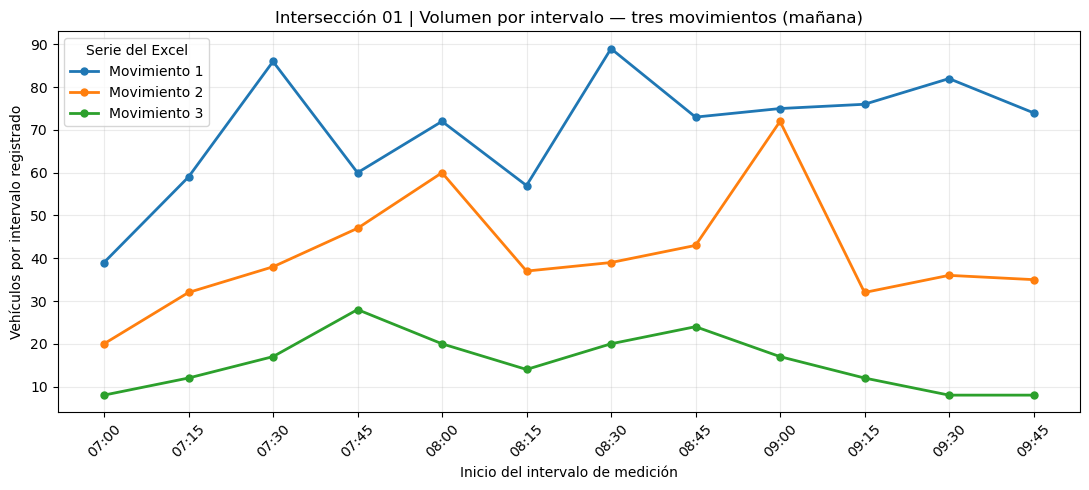

In [6]:
# Gráfica 1: evolución por intervalo de los tres movimientos
fig, ax = plt.subplots(figsize=(11, 5))
for movimiento in movimientos:
    ax.plot(datos["Intervalo"], datos[movimiento],
            marker="o", linewidth=2, markersize=5, label=movimiento)
ax.set_title("Intersección 01 | Volumen por intervalo — tres movimientos (mañana)")
ax.set_xlabel("Inicio del intervalo de medición")
ax.set_ylabel("Vehículos por intervalo registrado")
ax.grid(alpha=0.25)
ax.legend(title="Serie del Excel")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

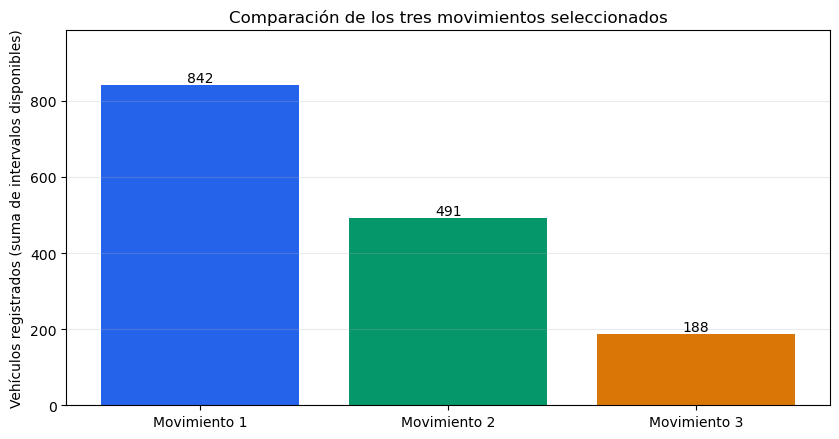

Mayor volumen acumulado: Movimiento 1 (842 vehículos)
Intervalo con mayor suma entre las tres series: 09:00
NOTA: estos resultados corresponden SOLO a las tres columnas seleccionadas.
No deben confundirse con la hora de máxima demanda de toda la intersección.


In [7]:
# Gráfica 2: volúmenes totales observados en los intervalos del Excel
totales = datos[movimientos].sum(axis=0, skipna=True)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
barras = ax.bar(movimientos, totales.values, color=["#2563eb", "#059669", "#d97706"])
for b, v in zip(barras, totales.values):
    ax.text(b.get_x()+b.get_width()/2, b.get_height(), f"{v:,.0f}",
            ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, max(totales.values) * 1.17)
ax.set_ylabel("Vehículos registrados (suma de intervalos disponibles)")
ax.set_title("Comparación de los tres movimientos seleccionados")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Comparación de los movimientos: máximo por serie y máximo conjunto por intervalo
datos["Suma de los tres"] = datos[movimientos].sum(axis=1, min_count=1)
mov_mayor = totales.idxmax()
intervalo_max = datos.loc[datos["Suma de los tres"].idxmax(), "Intervalo"]
print("Mayor volumen acumulado:", mov_mayor, f"({totales[mov_mayor]:,.0f} vehículos)")
print("Intervalo con mayor suma entre las tres series:", intervalo_max)
print("NOTA: estos resultados corresponden SOLO a las tres columnas seleccionadas.")
print("No deben confundirse con la hora de máxima demanda de toda la intersección.")

### Interpretación 2. Comportamiento del tráfico

**¿Cuál presenta mayor volumen?** El **Movimiento 1** suma **842 vehículos** durante las tres horas de observación, frente a **491** del Movimiento 2 y **188** del Movimiento 3.

**¿En qué intervalo se observa la mayor demanda?** Al sumar **solo los tres movimientos seleccionados**, el intervalo con más vehículos es **09:00–09:15, con 164 vehículos**. La hora de máxima demanda de **toda la intersección**, según el croquis, fue **08:00–09:00, con 1,771 vehículos**. Son mediciones de diferente alcance y duración.

**¿Se comportan de forma similar?** No completamente. El Movimiento 1 alcanza su máximo de **89 vehículos a las 08:30–08:45**; el Movimiento 2, **72 a las 09:00–09:15**; y el Movimiento 3, **28 a las 07:45–08:00**.

**¿Qué diferencias existen?** El Movimiento 1 tiene una demanda absoluta mayor que los otros dos, mientras que los momentos de máximo no coinciden. Sus perfiles horarios presentan fluctuaciones diferentes.

**¿Por qué es importante para repartir tiempos de verde?** Los movimientos pueden necesitar servicio diferente en función de la demanda, pero las duraciones deben considerar además capacidad de carriles, colas, coordinación, seguridad de cruces y peatones. Los conteos aislados no definen por sí solos los splits recomendados.

In [8]:
# Interpretación numérica directamente vinculada con los datos procesados
resumen = pd.DataFrame({
    "Volumen total": totales,
    "Máximo por intervalo": datos[movimientos].max(),
    "Intervalo del máximo": [
        datos.loc[datos[m].idxmax(), "Intervalo"] for m in movimientos
    ],
    "Desviación estándar": datos[movimientos].std()
})
display(resumen.round(2))
orden = totales.sort_values(ascending=False)
print(f"El movimiento de mayor volumen es {orden.index[0]} ({orden.iloc[0]:,.0f} vehículos).")
print(f"El de menor volumen es {orden.index[-1]} ({orden.iloc[-1]:,.0f} vehículos).")
print(f"La mayor suma de las tres series se produce en el intervalo {intervalo_max}.")
print("La desviación estándar resume la variabilidad observada de cada movimiento.")

,Volumen total,Máximo por intervalo,Intervalo del máximo,Desviación estándar
Movimiento 1,842.0,89.0,08:30,14.15
Movimiento 2,491.0,72.0,09:00,13.67
Movimiento 3,188.0,28.0,07:45,6.53


El movimiento de mayor volumen es Movimiento 1 (842 vehículos).
El de menor volumen es Movimiento 3 (188 vehículos).
La mayor suma de las tres series se produce en el intervalo 09:00.
La desviación estándar resume la variabilidad observada de cada movimiento.


---

## Parte 3. Normalización de los datos

La transformación Min-Max se calcula **independientemente para cada movimiento**:

\[
x_{\text{normalizado}}=\frac{x-x_{\min}}{x_{\max}-x_{\min}}.
\]

En los registros de 07:00–10:00, los extremos observados son:

| Movimiento | Mínimo | Máximo |
|---|---:|---:|
| 1 | 39 | 89 |
| 2 | 20 | 72 |
| 3 | 8 | 28 |

Por ejemplo, el valor de **89 vehículos** del Movimiento 1 se transforma en **1**, mientras que **39 vehículos** se convierte en **0**. Aunque dos movimientos tengan el valor normalizado 1, sus volúmenes originales pueden ser diferentes.

**Caso constante:** si un movimiento presenta el mismo volumen en todos los registros, el denominador es cero. En ese caso, la función del notebook le asigna valores normalizados **0**, deja constancia de la serie constante y conserva los valores faltantes sin convertirlos en conteos cero.

En una aplicación predictiva real, los mínimos y máximos se estimarían únicamente con el conjunto de entrenamiento.

In [9]:
# Normalización Min-Max por serie, con manejo explícito de constantes y NaN
normalizados = pd.DataFrame(index=datos.index)
constantes = []
for movimiento in movimientos:
    serie = datos[movimiento].astype(float)
    minimo, maximo = serie.min(), serie.max()
    if pd.isna(minimo):
        raise ValueError(f"El {movimiento} no tiene valores válidos.")
    if np.isclose(maximo, minimo):
        normalizados[movimiento] = serie.apply(lambda x: np.nan if pd.isna(x) else 0.0)
        constantes.append(movimiento)
    else:
        normalizados[movimiento] = (serie - minimo) / (maximo - minimo)

tabla_normalizacion = pd.DataFrame({"Intervalo": datos["Intervalo"]})
for movimiento in movimientos:
    tabla_normalizacion[f"{movimiento} original"] = datos[movimiento]
    tabla_normalizacion[f"{movimiento} Min-Max"] = normalizados[movimiento]

display(Markdown("### Tabla de valores originales y normalizados"))
display(tabla_normalizacion.round(4))
print("Movimientos constantes:", constantes if constantes else "ninguno")

valores_normalizados = normalizados.to_numpy(dtype=float)
assert np.all((valores_normalizados[np.isfinite(valores_normalizados)] >= -1e-10))
assert np.all((valores_normalizados[np.isfinite(valores_normalizados)] <= 1 + 1e-10))

### Tabla de valores originales y normalizados

,Intervalo,Movimiento 1 original,Movimiento 1 Min-Max,Movimiento 2 original,Movimiento 2 Min-Max,Movimiento 3 original,Movimiento 3 Min-Max
0,07:00,39.0,0.00,20.0,0.0000,8.0,0.00
1,07:15,59.0,0.40,32.0,0.2308,12.0,0.20
2,07:30,86.0,0.94,38.0,0.3462,17.0,0.45
3,07:45,60.0,0.42,47.0,0.5192,28.0,1.00
4,08:00,72.0,0.66,60.0,0.7692,20.0,0.60
5,08:15,57.0,0.36,37.0,0.3269,14.0,0.30
6,08:30,89.0,1.00,39.0,0.3654,20.0,0.60
7,08:45,73.0,0.68,43.0,0.4423,24.0,0.80
8,09:00,75.0,0.72,72.0,1.0000,17.0,0.45
9,09:15,76.0,0.74,32.0,0.2308,12.0,0.20


Movimientos constantes: ninguno


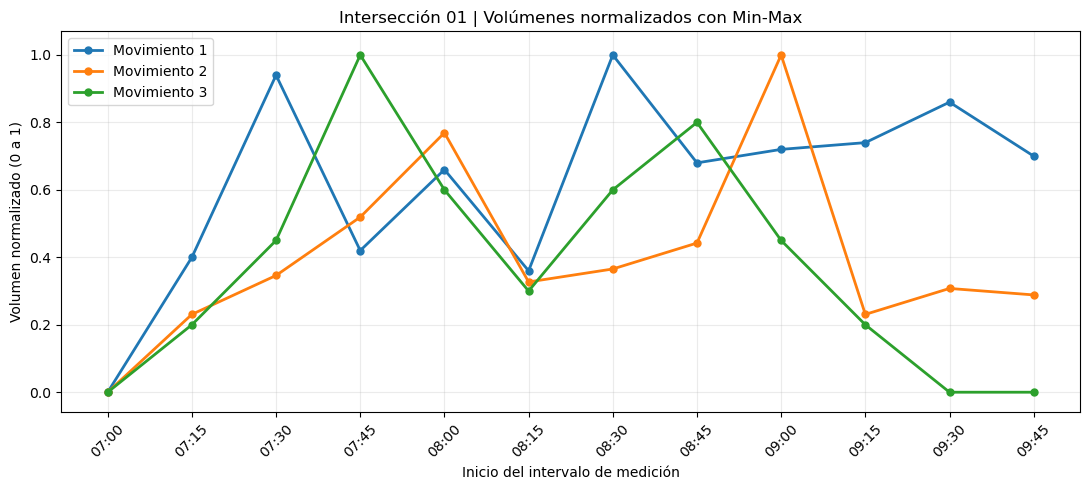

La primera gráfica muestra vehículos por intervalo; esta tercera gráfica muestra escala relativa.


In [10]:
# Gráfica 3: comparar las tres series normalizadas
fig, ax = plt.subplots(figsize=(11, 5))
for movimiento in movimientos:
    ax.plot(datos["Intervalo"], normalizados[movimiento],
            marker="o", linewidth=2, markersize=5, label=movimiento)
ax.set_title("Intersección 01 | Volúmenes normalizados con Min-Max")
ax.set_xlabel("Inicio del intervalo de medición")
ax.set_ylabel("Volumen normalizado (0 a 1)")
ax.set_ylim(-0.06, 1.07)
ax.grid(alpha=0.25)
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("La primera gráfica muestra vehículos por intervalo; esta tercera gráfica muestra escala relativa.")

### Interpretación 3. Normalización

**¿Qué cambió?** Los valores originales, que eran **vehículos por 15 minutos**, se convirtieron a una escala adimensional entre 0 y 1 mediante los mínimos y máximos observados de cada movimiento.

**¿Se conservaron los patrones?** Sí. En series no constantes, Min-Max es lineal y creciente, por lo que conserva las subidas, bajadas y posiciones de los máximos. Así, los máximos siguen ubicados a las **08:30 para el Movimiento 1**, **09:00 para el 2** y **07:45 para el 3**.

**¿Por qué ayuda para entrenar una MLP?** Permite entradas en magnitudes comparables, lo que suele facilitar un ajuste más estable de los pesos mediante optimización basada en gradientes.

**¿Normalizar implica el mismo volumen?** No. El valor normalizado 1 representa **89 vehículos** en el Movimiento 1, **72 en el 2** y **28 en el 3**. La normalización sirve para comparar patrones relativos, no volúmenes absolutos.

**¿Qué hacer con una columna constante?** Para esta actividad se asigna cero, evitando dividir entre cero. En un proyecto real se estudia si una variable sin variación aporta información.

**Prevención de fuga de información:** durante el entrenamiento de una MLP, el escalador se ajusta solo con datos de entrenamiento y luego se aplica a validación, prueba y operación sin volver a ajustarlo.

---

## Parte 4. Identificación de patrones para una futura MLP

### Propuesta de variables de entrada

| Variable candidata | ¿Qué información aporta? |
|---|---|
| Volumen del Movimiento 1 (veh./15 min) | Demanda de la primera corriente del acceso estudiado. |
| Volumen del Movimiento 2 (veh./15 min) | Demanda de la segunda corriente, distinta de la primera. |
| Volumen del Movimiento 3 (veh./15 min) | Demanda de la tercera corriente, de menor volumen en este estudio. |
| Hora del día | Identificación de patrones temporales de llegadas. |
| Ocupación y longitud de cola (requieren otros datos) | Congestión y acumulación de vehículos antes del semáforo. |

La MLP podría aprender relaciones entre hora, flujos de distintos movimientos, ocupación y colas. Los patrones detectados sugieren que **distintos movimientos alcanzan su mayor demanda en momentos diferentes**, y el controlador podría necesitar adaptar sus decisiones.

**Entradas frente a etiquetas:** los conteos de tráfico serían entradas. Las **etiquetas objetivo** serían tiempos de verde adecuados por fase (en segundos), obtenidos de registros confiables o mediante un esquema de optimización y validación. El Excel de volúmenes no proporciona por sí solo tales etiquetas, por lo que no es apropiado fabricar objetivos de entrenamiento. También se requieren reglas de fases, tiempos mínimos, intervalos de seguridad, demanda peatonal y restricciones del controlador.

### Interpretación 4. Conexión con las redes neuronales

**¿Qué datos utilizaría como entradas?** Los conteos reales de los movimientos 1, 2 y 3, junto con la hora. Para el reto completo agregaría volúmenes de los demás accesos, colas, ocupación, velocidades y demanda peatonal.

**¿Qué me gustaría que la red predijera?** Duraciones de verde o splits por fase que respondan al tráfico y cumplan restricciones de seguridad.

**¿Disponemos de etiquetas necesarias?** No se identificaron **tiempos de verde recomendados** como etiquetas en los datos de aforo. No basta con conocer la demanda para saber cuál es la asignación óptima de segundos.

**¿Qué diferencia hay entre ver un patrón y que una red lo aprenda?** La gráfica describe observaciones existentes; demostrar aprendizaje exige entrenar el modelo y comprobar que sus predicciones funcionan en datos no utilizados durante el ajuste.

**¿Cómo verificaría el modelo?** Separaría intervalos por tiempo o por días para evitar dependencia entre entrenamiento y prueba; ajustaría la normalización solo con el entrenamiento; evaluaría MAE/RMSE sobre tiempos de verde de referencia y compararía políticas semafóricas mediante simulación calibrada de demoras, colas y seguridad.

### Verificación final
Las comprobaciones finales contrastan los datos calculados con los valores **realmente registrados** en las hojas de movimientos del Excel y con el subtotal de **548 vehículos** indicado en el croquis para la hora pico matutina.

El notebook es exploratorio: no crea etiquetas de tiempos de verde ni entrena una red neuronal.

In [11]:
# Comprobaciones de consistencia del análisis real
assert libro.sheet_names == ["Hora Máx.", *[str(i) for i in range(1, 15)], "Vol. Dir."]
assert len(datos) == 12
assert len(movimientos) == 3
assert not datos[movimientos].isna().any().any()
assert totales.astype(int).tolist() == [842, 491, 188]
assert hora_pico.astype(int).tolist() == [291, 179, 78]
assert int(hora_pico.sum()) == 548
assert intervalo_max == "09:00"
assert int(datos["Suma de los tres"].max()) == 164
assert normalizados.shape == (12, 3)
print("Comprobación satisfactoria: 16 hojas, 12 intervalos de 15 min.")
print("Movimientos 1, 2 y 3 verificados con registros del Excel.")
print("Hora pico del acceso: 291 + 179 + 78 = 548 vehículos.")
print("No se entrenó una red neuronal.")

Comprobación satisfactoria: 16 hojas, 12 intervalos de 15 min.
Movimientos 1, 2 y 3 verificados con registros del Excel.
Hora pico del acceso: 291 + 179 + 78 = 548 vehículos.
No se entrenó una red neuronal.


---

## Conclusión: ¿qué aprendí sobre los datos de tráfico?

Con esta actividad comprendí que analizar la información es una etapa indispensable antes de desarrollar una red neuronal para resolver un problema de tránsito. Al revisar el archivo de la intersección 01, identifiqué que los aforos están organizados por movimiento y que cada registro representa 15 minutos. Esto permitió observar cómo cambia la demanda a lo largo de la mañana y comparar distintas corrientes del mismo acceso.

Los resultados muestran diferencias importantes: entre las 07:00 y las 10:00, el Movimiento 1 acumuló 842 vehículos, el Movimiento 2 registró 491 y el Movimiento 3 tuvo 188. Además, sus máximos se presentaron en intervalos diferentes, lo cual demuestra que no todos los movimientos siguen exactamente el mismo patrón.

La normalización Min-Max me permitió comparar esas variaciones en una escala común, pero también entendí que dos valores normalizados iguales no significan que haya circulado la misma cantidad de vehículos.

Para el reto de SEMEX, considero que lo más importante es comprender qué información está disponible y cuál todavía falta. Estos volúmenes pueden servir como entradas de una MLP, pero necesitamos etiquetas de tiempos de verde, información sobre colas y restricciones operativas antes de entrenar un modelo y comprobar si sus predicciones realmente contribuyen a reducir las demoras.